# MSDM5054 — Member D: neural networks NN2, NN3, NN4

Recursive out-of-sample evaluation of Gu, Kelly & Xiu (2020), 1987–2016, run with the team code
package (`src/`, unmodified) on a local Apple M3 CPU.

**Reduction plan (schedule §7) applied — announced in the group chat before the run**

1. `cfg.refit_every = 2` — one refit every two years (15 refits covering the 30 test years).
2. `n_ensemble = 3` — 3 independently seeded networks per refit instead of 5.

Variable importance is computed at the six refit years 1987, 1993, 1999, 2005, 2011, 2015
(the reduction keeps the six VI snapshots, just at odd years).

## 0. Setup

In [1]:
import os, sys, json, glob, time
from pathlib import Path
PROJECT_DIR = "/Users/<user>/Desktop/5054"
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from src.config import Config
from src.panel import Panel
from src import recursive as R, metrics as M

QUICK = False
MY_MODELS = ["NN3", "NN2", "NN4"]      # NN3 first (schedule priority)

cfg = Config()
cfg.refit_every = 2                    # reduction #2
cfg.vi_years = (1987, 1993, 1999, 2005, 2011, 2015)
print("refit years :", cfg.refit_years())
print("test years  :", cfg.test_start, "-", cfg.test_end)
print("n_ensemble  : 3   | refit_every :", cfg.refit_every, "| tune_every : 5")
print("models      :", MY_MODELS)

refit years : [1987, 1989, 1991, 1993, 1995, 1997, 1999, 2001, 2003, 2005, 2007, 2009, 2011, 2013, 2015]
test years  : 1987 - 2016
n_ensemble  : 3   | refit_every : 2 | tune_every : 5
models      : ['NN3', 'NN2', 'NN4']


In [2]:
pan = Panel(cfg)
print(f"sample: {pan.n:,} rows, {pan.year.min()}-{pan.year.max()}, "
      f"{pan.n_features} inputs ({len(pan.chars)} chars x 9 + {pan.n_sic} sic2 dummies)")

panel: 4,339,257 rows | 94 chars | 8 macro | 74 sic2 codes | 920 features | 1927-2020
sample: 4,339,257 rows, 1927-2020, 920 inputs (94 chars x 9 + 74 sic2 dummies)


## 5. Neural networks NN2–NN4

`run_model` is resumable: a refit whose `pred_<year>.parquet` already exists is skipped, so the
cell below re-runs instantly on an existing `outputs/` and continues where a disconnected run stopped.

In [3]:
NN_KW = dict(n_ensemble=3)             # reduction #1 (paper: 10, team default non-QUICK: 5)
for name in MY_MODELS:
    t0 = time.time()
    R.run_model(name, pan, cfg, tune_every=5, **NN_KW)
    print(f"== {name}: {(time.time()-t0)/60:.1f} min this pass ==")

[NN3] 1987: done, skipping
[NN3] 1989: done, skipping
[NN3] 1991: done, skipping
[NN3] 1993: done, skipping
[NN3] 1995: done, skipping
[NN3] 1997: done, skipping
[NN3] 1999: done, skipping
[NN3] 2001: done, skipping
[NN3] 2003: done, skipping
[NN3] 2005: done, skipping
[NN3] 2007: done, skipping
[NN3] 2009: done, skipping
[NN3] 2011: done, skipping
[NN3] 2013: done, skipping
[NN3] 2015: done, skipping
== NN3: 0.0 min this pass ==
[NN2] 1987: done, skipping
[NN2] 1989: done, skipping
[NN2] 1991: done, skipping
[NN2] 1993: done, skipping
[NN2] 1995: done, skipping
[NN2] 1997: done, skipping
[NN2] 1999: done, skipping
[NN2] 2001: done, skipping
[NN2] 2003: done, skipping
[NN2] 2005: done, skipping
[NN2] 2007: done, skipping
[NN2] 2009: done, skipping
[NN2] 2011: done, skipping
[NN2] 2013: done, skipping
[NN2] 2015: done, skipping
== NN2: 0.0 min this pass ==
[NN4] 1987: done, skipping
[NN4] 1989: done, skipping
[NN4] 1991: done, skipping
[NN4] 1993: done, skipping
[NN4] 1995: done, skippi

## 6. Results — my models

In [4]:
# progress check: how many refits / test years are stored per model
rows = []
for m in MY_MODELS:
    files = sorted((OUT_DIR := Path(cfg.out_dir) / m).glob("pred_*.parquet"))
    d = M.load_preds(cfg.out_dir, m)
    years = sorted(pd.to_datetime(d.date).dt.year.unique()) if len(d) else []
    rows.append(dict(model=m, refit_files=len(files), test_years=len(years),
                     first=years[0] if years else None, last=years[-1] if years else None,
                     vi_files=len(list((Path(cfg.out_dir) / m).glob("vi_*.csv")))))
print(pd.DataFrame(rows).to_string(index=False))

model  refit_files  test_years  first  last  vi_files
  NN3           15          30   1987  2016         6
  NN2           15          30   1987  2016         6
  NN4           15          30   1987  2016         6


In [5]:
r2 = M.r2_table(cfg.out_dir, models=MY_MODELS)
print(r2.round(3).to_string())

       All  Top 1000  Bottom 1000      years  Paper (All)
NN3  0.211     0.357        0.379  1987-2016         0.40
NN2  0.315     0.611        0.357  1987-2016         0.39
NN4  0.193     0.317        0.384  1987-2016         0.39


In [6]:
r2y = M.r2_by_year(cfg.out_dir, models=MY_MODELS)
print(r2y.round(2).to_string())
print()
print("average across the 30 test years (%):")
print(r2y.mean().round(3).to_string())

       NN3   NN2   NN4
year                  
1987 -0.66  0.01 -0.43
1988  0.33  0.35  0.15
1989  0.03  0.14 -0.07
1990 -0.66 -0.16 -0.90
1991  0.22  0.58  0.54
1992  0.16  0.51  0.37
1993  0.46  0.30  0.58
1994 -0.65 -0.08 -0.75
1995  0.74  0.91  0.38
1996  0.41  0.50 -0.65
1997  0.65  0.69  0.68
1998  0.23  0.08  0.11
1999 -0.09  0.35  0.31
2000  0.45  0.49  0.26
2001  1.01  0.66  1.05
2002  0.81  0.84  0.69
2003  0.78  1.37  1.38
2004  0.68  0.73  0.54
2005 -0.98 -0.98 -1.33
2006 -0.36 -0.48 -0.58
2007 -2.38 -2.12 -2.38
2008 -2.29 -1.81 -2.01
2009  2.33  1.27  2.18
2010  0.79  1.32  0.82
2011 -0.53 -0.97 -0.80
2012  0.33  0.70  0.40
2013  1.99  1.70  1.95
2014 -1.54 -1.28 -1.34
2015 -0.69 -0.59 -0.63
2016 -0.57  0.08 -0.78

average across the 30 test years (%):
NN3    0.033
NN2    0.170
NN4   -0.008


In [7]:
# how long each refit took (from hparams_*.json) — needed for notes.txt
for m in MY_MODELS:
    h = M.hparam_history(cfg.out_dir, m, "minutes")
    secs = pd.Series({int(f.stem.split("_")[1]): json.load(open(f))["seconds"]
                      for f in sorted((Path(cfg.out_dir) / m).glob("hparams_*.json"))}) / 60
    print(f"{m}: {len(secs)} refits, total {secs.sum():.0f} min, "
          f"median {secs.median():.1f} min/refit, max {secs.max():.1f} min")

NN3: 15 refits, total 52 min, median 2.8 min/refit, max 11.5 min
NN2: 15 refits, total 38 min, median 2.3 min/refit, max 7.4 min
NN4: 15 refits, total 43 min, median 2.0 min/refit, max 6.1 min


In [8]:
ch, mc = M.variable_importance(cfg.out_dir, models=MY_MODELS, normalise=True)
print("top-10 characteristics (share of total importance):")
print((ch.mean(1).sort_values(ascending=False).head(10)).round(4).to_string())
print()
print("macro predictors:")
print(mc.round(4).to_string())

top-10 characteristics (share of total importance):
mom1m       0.2323
mvel1       0.1041
retvol      0.1014
turn        0.0810
maxret      0.0578
chmom       0.0571
std_turn    0.0565
dolvol      0.0454
mom12m      0.0363
mom6m       0.0295

macro predictors:
         NN3     NN2     NN4
dp    0.5999  0.6890  0.6374
ep_m  0.2490  0.1874  0.2512
bm_m  0.1511  0.1232  0.1114
ntis  0.0000  0.0000  0.0000
tbl   0.0000  0.0003  0.0000
tms   0.0000  0.0000  0.0000
dfy   0.0000  0.0000  0.0000
svar  0.0000  0.0000  0.0000


/var/folders/fw/km2qmsm91zg7qkx96k4vctfw0000gn/T/ipykernel_1726/3853596001.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  print((ch.mean(1).sort_values(ascending=False).head(10)).round(4).to_string())


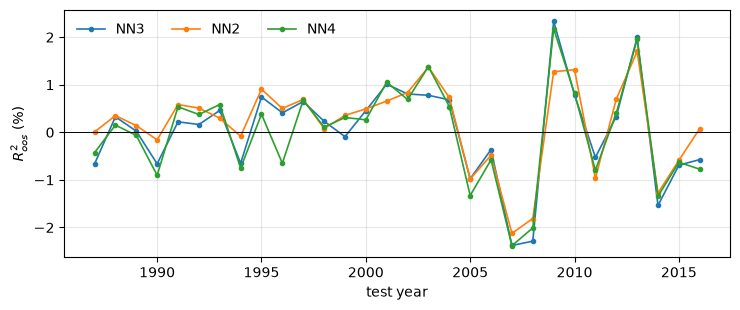

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
r2y.plot(ax=ax, lw=1.2, marker=".")
ax.axhline(0, color="k", lw=0.7)
ax.set_ylabel(r"$R^2_{oos}$ (%)"); ax.set_xlabel("test year")
ax.grid(alpha=.3); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.show()

### What was run, in one line

15 refits x 3 models, each refit = 6-point hyper-parameter grid at every 5th refit (1987, 1997,
2007) + 3 ensemble members; CPU only (Apple M3), ~1.5-5.5 s per epoch, early stopping patience 5.